In [54]:
import gcinfo
import pandas as pd
from io import StringIO

# NOTE(Ryan): Censored cells set to 5
#
# Data Source: IRCC COGNOS – Detentions Datamart
# Prepared by: Statistics and Performance Metrics Unit, Intelligence and Enforcement Branch
# Extracted: 2026-07-02
# Notes: Detention statistics for the 2024 calendar year, broken down by country of citizenship.
#
# Citizenship,"# of Detainees"
df_detainees_2024 = pd.read_csv(StringIO("""\
Citizenship,Detainees
Afghanistan,11
Albania,16
Algeria,127
Angola,7
Antigua and Barbuda,5
Argentina,5
Australia,5
Azerbaijan,5
"Bahama Islands, The",14
Bahrain,5
Bangladesh,44
Barbados,20
Belarus,5
Belgium,10
Belize,5
Bermuda,5
Bolivia,6
Bosnia-Hercegovina,5
Brazil,25
British Dependent Territories Citizen,5
Bulgaria,5
Burkina-Faso,5
Burundi,10
Cambodia,5
Canada,5
Cape Verde Islands,5
"Chad, Republic of",5
Chile,115
Colombia,98
"Congo, Democratic Republic of the",32
"Congo, People's Republic of the",5
Costa Rica,5
Croatia,5
Cuba,14
Cyprus,5
Czech Republic,5
Democratic Republic of Sudan,10
Denmark,5
Dominica,5
Dominican Republic,27
Ecuador,10
Egypt,10
El Salvador,20
Eritrea,8
Ethiopia,8
Federal Republic of Cameroon,25
Federal Republic of Germany,12
Fiji,5
France,37
Gabon Republic,5
Gambia,6
Georgia,15
Ghana,53
Greece,7
Guatemala,27
"Guinea, Republic of",23
Guyana,12
Haiti,38
Honduras,11
Hong Kong SAR,9
Hungary,20
India,794
Iran,27
Iraq,18
Israel,12
Italy,10
Jamaica,118
Japan,17
Jordan,21
Kazakhstan,5
Kenya,26
"Korea, Republic of",27
Laos,5
Latvia,5
Lebanon,7
Liberia,5
Libya,5
Lithuania,5
Macedonia,5
Malaysia,5
"Mali, Republic of",5
Malta,5
Mauritius,5
Mexico,680
Moldova,5
"Mongolia, People's Republic of",5
Morocco,34
Myanmar (Burma),5
Namibia,6
Nepal,7
New Zealand,5
Nicaragua,8
Nigeria,165
Norway,5
Pakistan,39
Palestinian Authority (Gaza/West Bank),5
"Panama, Republic of",5
People's Republic of Benin,5
People's Republic of China,105
Peru,17
Philippines,31
Poland,31
Portugal,24
Republic of Djibouti,5
Republic of Indonesia,5
Republic of Ireland,28
Republic of Ivory Coast,17
Republic of South Africa,5
Republic of the Niger,5
Romania,282
Russia,8
Rwanda,10
Senegal,22
"Serbia, Republic of",5
Sierra Leone,7
Singapore,5
Slovak Republic,5
Socialist Republic of Vietnam,80
"Somalia, Democratic Republic of",41
"South Sudan, Republic of",7
Spain,29
Sri Lanka,56
St. Kitts-Nevis,5
St. Lucia,9
St. Vincent and the Grenadines,21
Stateless,5
Sweden,13
Switzerland,5
Syria,6
Taiwan,10
Tajikistan,5
Thailand,6
The Netherlands,9
"Togo, Republic of",5
"Trinidad and Tobago, Republic of",11
Tunisia,18
Turkey,22
Uganda,6
UK - Brit. Nat. Overseas,5
UK - British citizen,87
Ukraine,6
United Kingdom and Colonies,5
United Republic of Tanzania,6
United States of America,147
Unknown,5
Uzbekistan,5
Vanuatu,5
Venezuela,5
"Yemen, Republic of",5
Zambia,5
Zimbabwe,10"""))
df_detainees_2024 = df_detainees_2024.sort_values(by="Detainees", ascending=False)
df_detainees_2024_original = df_detainees_2024
df_detainees_2024

,Citizenship,Detainees
61,India,794
83,Mexico,680
109,Romania,282
92,Nigeria,165
143,United States of America,147
...,...,...
144,Unknown,5
146,Vanuatu,5
147,Venezuela,5
148,"Yemen, Republic of",5


In [55]:
df_detainees_2024.head(10)

,Citizenship,Detainees
61,India,794
83,Mexico,680
109,Romania,282
92,Nigeria,165
143,United States of America,147
2,Algeria,127
66,Jamaica,118
27,Chile,115
98,People's Republic of China,105
28,Colombia,98


In [56]:
df_birth_2021, df_birth_2021_meta = gcinfo.download_zip("https://www150.statcan.gc.ca/n1/tbl/csv/98100361-eng.zip")

Using cached file: cache\98100361-eng.zip


In [57]:
df_birth_2021_canada = df_birth_2021[df_birth_2021["GEO"] == "Canada"]
df_birth_2021_canada["GEO"].astype(str).unique()

array(['Canada'], dtype=object)

In [58]:
aggregates = ["Total – Place of birth",

              "Inside Canada",
              "Newfoundland and Labrador", "Prince Edward Island", "Nova Scotia", "New Brunswick", "Quebec", "Ontario", "Manitoba",
              "Saskatchewan", "Alberta", "British Columbia", "Yukon", "Northwest Territories", "Nunavut",

              "Outside Canada",
              "Americas",
              "North America", "Central America", "Caribbean and Bermuda", "South America",
              "Europe",
              "Western Europe", "Eastern Europe", "Northern Europe", "Southern Europe",
              "Africa",
              "Western Africa", "Eastern Africa", "Northern Africa", "Central Africa", "Southern Africa",
              "Asia",
              "West Central Asia and the Middle East", "Eastern Asia", "Southeast Asia", "Southern Asia",
              "Oceania",
              "Antarctica and Adjacent Islands",
              "Other",
]

In [59]:
# df_birth_2021_canada[~df_birth_2021_canada["Place of birth (290)"].isin(aggregates)]["Place of birth (290)", "Total - Non-permanent resident type[1]"].head()
df_birth_2021_canada_nations = df_birth_2021_canada[~df_birth_2021_canada["Place of birth (290)"].isin(aggregates)]
df_birth_2021_canada_nations

,REF_DATE,GEO,DGUID,Gender (3),Age (15C),Statistics (3),Place of birth (290),Coordinate,Non-permanent resident type (10):Total - Non-permanent resident type[1],Symbol,...,Non-permanent resident type (10):Non-permanent residents with work and study permits[6],Symbol.5,Non-permanent resident type (10):Other non-permanent resident types[7],Symbol.6,Non-permanent resident type (10):Not a non-permanent resident[8],Symbol.7,Non-permanent resident type (10):Non-immigrants[9],Symbol.8,Non-permanent resident type (10):Immigrants[10],Symbol.9
18,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Greenland,1.1.1.1.19,30,NaN,...,0,NaN,0,NaN,25,NaN,0,NaN,25,NaN
19,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Saint Pierre and Miquelon,1.1.1.1.20,510,NaN,...,15,NaN,0,NaN,465,NaN,105,NaN,355,NaN
20,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,United States of America,1.1.1.1.21,373380,NaN,...,1155,NaN,4565,NaN,346575,NaN,90485,NaN,256085,NaN
22,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Belize,1.1.1.1.23,2940,NaN,...,30,NaN,15,NaN,2750,NaN,735,NaN,2015,NaN
23,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Costa Rica,1.1.1.1.24,5890,NaN,...,55,NaN,35,NaN,5315,NaN,655,NaN,4655,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39143,2021,Canada,2021A000011124,Women+,75 years and over,"95% confidence interval upper bound, Count",Wallis and Futuna,1.3.15.3.284,0,...,...,0,...,0,...,0,...,0,...,0,...
39145,2021,Canada,2021A000011124,Women+,75 years and over,"95% confidence interval upper bound, Count",Antarctica,1.3.15.3.286,0,...,...,0,...,0,...,0,...,0,...,0,...
39146,2021,Canada,2021A000011124,Women+,75 years and over,"95% confidence interval upper bound, Count",Bouvet Island,1.3.15.3.287,0,...,...,0,...,0,...,0,...,0,...,0,...
39147,2021,Canada,2021A000011124,Women+,75 years and over,"95% confidence interval upper bound, Count",French Southern Territories,1.3.15.3.288,0,...,...,0,...,0,...,0,...,0,...,0,...


In [60]:
df_birth_2021_canada_nations_clean = df_birth_2021_canada_nations[
    (df_birth_2021_canada_nations["Gender (3)"] == "Total - Gender") &
    (df_birth_2021_canada_nations["Age (15C)"] == "Total - Age") &
    (df_birth_2021_canada_nations["Statistics (3)"] == "Count")
]
df_birth_2021_canada_nations_clean

,REF_DATE,GEO,DGUID,Gender (3),Age (15C),Statistics (3),Place of birth (290),Coordinate,Non-permanent resident type (10):Total - Non-permanent resident type[1],Symbol,...,Non-permanent resident type (10):Non-permanent residents with work and study permits[6],Symbol.5,Non-permanent resident type (10):Other non-permanent resident types[7],Symbol.6,Non-permanent resident type (10):Not a non-permanent resident[8],Symbol.7,Non-permanent resident type (10):Non-immigrants[9],Symbol.8,Non-permanent resident type (10):Immigrants[10],Symbol.9
18,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Greenland,1.1.1.1.19,30,NaN,...,0,NaN,0,NaN,25,NaN,0,NaN,25,NaN
19,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Saint Pierre and Miquelon,1.1.1.1.20,510,NaN,...,15,NaN,0,NaN,465,NaN,105,NaN,355,NaN
20,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,United States of America,1.1.1.1.21,373380,NaN,...,1155,NaN,4565,NaN,346575,NaN,90485,NaN,256085,NaN
22,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Belize,1.1.1.1.23,2940,NaN,...,30,NaN,15,NaN,2750,NaN,735,NaN,2015,NaN
23,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Costa Rica,1.1.1.1.24,5890,NaN,...,55,NaN,35,NaN,5315,NaN,655,NaN,4655,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Wallis and Futuna,1.1.1.1.284,15,NaN,...,0,NaN,0,NaN,15,NaN,0,NaN,15,NaN
285,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Antarctica,1.1.1.1.286,0,NaN,...,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN
286,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,Bouvet Island,1.1.1.1.287,0,NaN,...,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN
287,2021,Canada,2021A000011124,Total - Gender,Total - Age,Count,French Southern Territories,1.1.1.1.288,0,NaN,...,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN


In [61]:
df_birth_2021_canada_nations_clean = df_birth_2021_canada_nations_clean[[
    "Place of birth (290)",
    "Non-permanent resident type (10):Total - Non-permanent resident type[1]"
]].sort_values("Non-permanent resident type (10):Total - Non-permanent resident type[1]", ascending=False)
df_birth_2021_canada_nations_clean_original = df_birth_2021_canada_nations_clean.copy()
df_birth_2021_canada_nations_clean

,Place of birth (290),Non-permanent resident type (10):Total - Non-permanent resident type[1]
250,India,1166755
226,China,830985
241,Philippines,757415
115,United Kingdom,506035
20,United States of America,373380
...,...,...
280,Tuvalu,0
285,Antarctica,0
286,Bouvet Island,0
287,French Southern Territories,0


In [62]:
df_birth_2021_canada_nations_clean["Place of birth (290)"].unique()

array(['India', 'China', 'Philippines', 'United Kingdom',
       'United States of America', 'Pakistan', 'Hong Kong', 'Iran',
       'Italy', 'Viet Nam', 'France', 'Korea, South', 'Jamaica',
       'Germany', 'Sri Lanka', 'Poland', 'Portugal', 'Mexico', 'Haiti',
       'Nigeria', 'Lebanon', 'Syria', 'Colombia', 'Morocco', 'Romania',
       'Algeria', 'Ukraine', 'Russian Federation', 'Guyana', 'Iraq',
       'Netherlands', 'Egypt', 'Bangladesh', 'Brazil', 'Taiwan',
       'Trinidad and Tobago', 'Afghanistan', 'Greece',
       'South Africa, Republic of', 'El Salvador', 'Ethiopia', 'Turkey',
       'Japan', 'Congo, Democratic Republic of the', 'Saudi Arabia',
       'Croatia', 'Bosnia and Herzegovina', 'Australia',
       'United Arab Emirates', 'Ireland', 'Peru', 'Somalia', 'Israel',
       'Venezuela', 'Cameroon', 'Hungary', 'Kenya', 'Serbia', 'Eritrea',
       'Chile', 'Tunisia', 'Ghana', 'Malaysia', 'Fiji', 'Cambodia',
       'Tanzania', "Côte d'Ivoire", 'Belgium', 'Nepal', 'Switzerl

In [63]:
map_detainees_birth = {'Algeria': 'Algeria',
 'Bangladesh': 'Bangladesh',
 'Chile': 'Chile',
 'Colombia': 'Colombia',
 'Congo, Democratic Republic of the': 'Congo, Democratic Republic of the',
 'Dominican Republic': 'Dominican Republic',
 'France': 'France',
 'Ghana': 'Ghana',
 'Guatemala': 'Guatemala',
 'Haiti': 'Haiti',
 'India': 'India',
 'Iran': 'Iran',
 'Jamaica': 'Jamaica',
 'Kenya': 'Kenya',
 'Korea, Republic of': 'Korea, South',
 'Mexico': 'Mexico',
 'Morocco': 'Morocco',
 'Nigeria': 'Nigeria',
 'Pakistan': 'Pakistan',
 "People's Republic of China": 'China',
 'Philippines': 'Philippines',
 'Republic of Indonesia': 'Indonesia',
 'Republic of Ireland': 'Ireland',
 'Romania': 'Romania',
 'Socialist Republic of Vietnam': 'Viet Nam',
 'Somalia, Democratic Republic of': 'Somalia',
 'Spain': 'Spain',
 'Sri Lanka': 'Sri Lanka',
 'UK - British citizen': 'United Kingdom',
 'United States of America': 'United States of America'
}

In [64]:
map_birth_detainees = {v: k for k, v in map_detainees_birth.items()}
map_birth_detainees

{'Algeria': 'Algeria',
 'Bangladesh': 'Bangladesh',
 'Chile': 'Chile',
 'Colombia': 'Colombia',
 'Congo, Democratic Republic of the': 'Congo, Democratic Republic of the',
 'Dominican Republic': 'Dominican Republic',
 'France': 'France',
 'Ghana': 'Ghana',
 'Guatemala': 'Guatemala',
 'Haiti': 'Haiti',
 'India': 'India',
 'Iran': 'Iran',
 'Jamaica': 'Jamaica',
 'Kenya': 'Kenya',
 'Korea, South': 'Korea, Republic of',
 'Mexico': 'Mexico',
 'Morocco': 'Morocco',
 'Nigeria': 'Nigeria',
 'Pakistan': 'Pakistan',
 'China': "People's Republic of China",
 'Philippines': 'Philippines',
 'Indonesia': 'Republic of Indonesia',
 'Ireland': 'Republic of Ireland',
 'Romania': 'Romania',
 'Viet Nam': 'Socialist Republic of Vietnam',
 'Somalia': 'Somalia, Democratic Republic of',
 'Spain': 'Spain',
 'Sri Lanka': 'Sri Lanka',
 'United Kingdom': 'UK - British citizen',
 'United States of America': 'United States of America'}

In [65]:
_debug = df_detainees_2024[df_detainees_2024["Detainees"] > 25]
print(_debug.shape)
_debug

(30, 2)


,Citizenship,Detainees
61,India,794
83,Mexico,680
109,Romania,282
92,Nigeria,165
143,United States of America,147
2,Algeria,127
66,Jamaica,118
27,Chile,115
98,People's Republic of China,105
28,Colombia,98


In [66]:
# _debug["Citizenship"]= _debug["Citizenship"].map(map_detainees_birth)
# _debug

In [67]:
_debug.shape

(30, 2)

In [68]:
df_birth_2021_canada_nations_clean["Place of birth (290)"].unique().tolist()

['India',
 'China',
 'Philippines',
 'United Kingdom',
 'United States of America',
 'Pakistan',
 'Hong Kong',
 'Iran',
 'Italy',
 'Viet Nam',
 'France',
 'Korea, South',
 'Jamaica',
 'Germany',
 'Sri Lanka',
 'Poland',
 'Portugal',
 'Mexico',
 'Haiti',
 'Nigeria',
 'Lebanon',
 'Syria',
 'Colombia',
 'Morocco',
 'Romania',
 'Algeria',
 'Ukraine',
 'Russian Federation',
 'Guyana',
 'Iraq',
 'Netherlands',
 'Egypt',
 'Bangladesh',
 'Brazil',
 'Taiwan',
 'Trinidad and Tobago',
 'Afghanistan',
 'Greece',
 'South Africa, Republic of',
 'El Salvador',
 'Ethiopia',
 'Turkey',
 'Japan',
 'Congo, Democratic Republic of the',
 'Saudi Arabia',
 'Croatia',
 'Bosnia and Herzegovina',
 'Australia',
 'United Arab Emirates',
 'Ireland',
 'Peru',
 'Somalia',
 'Israel',
 'Venezuela',
 'Cameroon',
 'Hungary',
 'Kenya',
 'Serbia',
 'Eritrea',
 'Chile',
 'Tunisia',
 'Ghana',
 'Malaysia',
 'Fiji',
 'Cambodia',
 'Tanzania',
 "Côte d'Ivoire",
 'Belgium',
 'Nepal',
 'Switzerland',
 'Argentina',
 'Cuba',
 'Guat

In [69]:
df_birth_2021_canada_nations_clean["Place of birth (290)"] = df_birth_2021_canada_nations_clean["Place of birth (290)"].replace(map_birth_detainees)
print(df_birth_2021_canada_nations_clean.shape)
df_birth_2021_canada_nations_clean

(250, 2)


,Place of birth (290),Non-permanent resident type (10):Total - Non-permanent resident type[1]
250,India,1166755
226,People's Republic of China,830985
241,Philippines,757415
115,UK - British citizen,506035
20,United States of America,373380
...,...,...
280,Tuvalu,0
285,Antarctica,0
286,Bouvet Island,0
287,French Southern Territories,0


In [70]:
df_birth_2021_canada_nations_clean = df_birth_2021_canada_nations_clean[df_birth_2021_canada_nations_clean["Place of birth (290)"].isin(_debug["Citizenship"].unique().tolist())]
print(df_birth_2021_canada_nations_clean.shape)
df_birth_2021_canada_nations_clean

(30, 2)


,Place of birth (290),Non-permanent resident type (10):Total - Non-permanent resident type[1]
250,India,1166755
226,People's Republic of China,830985
241,Philippines,757415
115,UK - British citizen,506035
20,United States of America,373380
253,Pakistan,245520
206,Iran,213160
245,Socialist Republic of Vietnam,202335
80,France,177715
230,"Korea, Republic of",170880


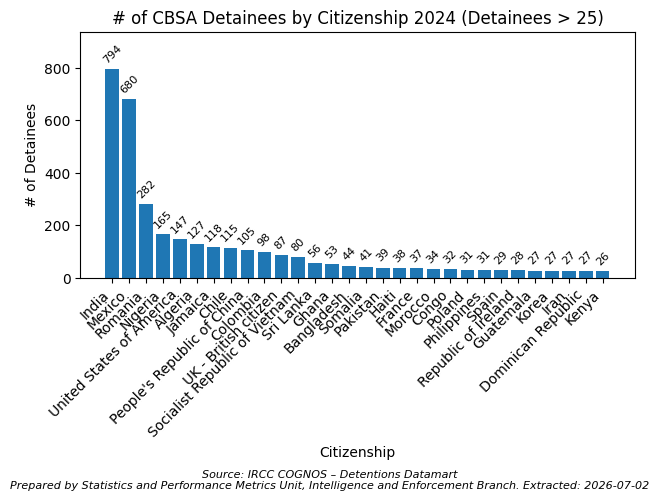

In [71]:
import matplotlib.pyplot as plt

X = 25
# Assume df_detainees_2024 already exists with columns "Citizenship" and "Detainees"
# Sort descending by Detainees for readability
df_plot = df_detainees_2024.sort_values("Detainees", ascending=False)
df_plot = df_plot[df_plot["Detainees"] > X]
df_plot["Citizenship"] = df_plot["Citizenship"].apply(lambda x: x.split(",")[0])

fig, ax = plt.subplots()
bars = ax.bar(df_plot["Citizenship"], df_plot["Detainees"])

# Add value labels on top of each bar (rotated 45°)
ax.bar_label(bars, padding=3, fontsize=8, rotation=45)

# Add a little extra headroom so labels aren't clipped
ax.margins(y=0.18)

ax.set_title(f"# of CBSA Detainees by Citizenship 2024 (Detainees > {X})")
ax.set_xlabel("Citizenship")
ax.set_ylabel("# of Detainees")

plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.3)
plt.figtext(
    0.5, -0.03,
    "Source: IRCC COGNOS – Detentions Datamart\n"
    "Prepared by Statistics and Performance Metrics Unit, Intelligence and Enforcement Branch. Extracted: 2026-07-02",
    ha="center",
    fontsize=8,
    style="italic"
)
plt.tight_layout()
plt.show()

In [72]:
import matplotlib.pyplot as plt
import pandas as pd

# Merge the two dataframes on nation name
df_pop = df_birth_2021_canada_nations_clean.rename(
    columns={
        "Place of birth (290)": "Nation",
        "Non-permanent resident type (10):Total - Non-permanent resident type[1]": "Population"
    }
)

df_det = _debug.rename(
    columns={
        "Citizenship": "Nation",
        "Detainees": "Detainees"
    }
)

df = pd.merge(df_pop, df_det, on="Nation", how="inner")

# Detainees per capita (per 1000 non-permanent residents for readability)
df["Detainees_per_1000"] = (df["Detainees"] / df["Population"]) * 1000

# Sort descending for a clearer bar chart
df = df.sort_values("Detainees_per_1000", ascending=False)
df

,Nation,Population,Detainees,Detainees_per_1000
13,Mexico,132220,680,5.142944
25,Chile,31565,115,3.643276
18,Romania,88645,282,3.181228
29,Spain,15025,29,1.930116
26,Ghana,29110,53,1.820680
28,Dominican Republic,15640,27,1.726343
15,Nigeria,111470,165,1.480219
19,Algeria,87835,127,1.445893
27,Guatemala,21150,27,1.276596
23,"Somalia, Democratic Republic of",34115,41,1.201817


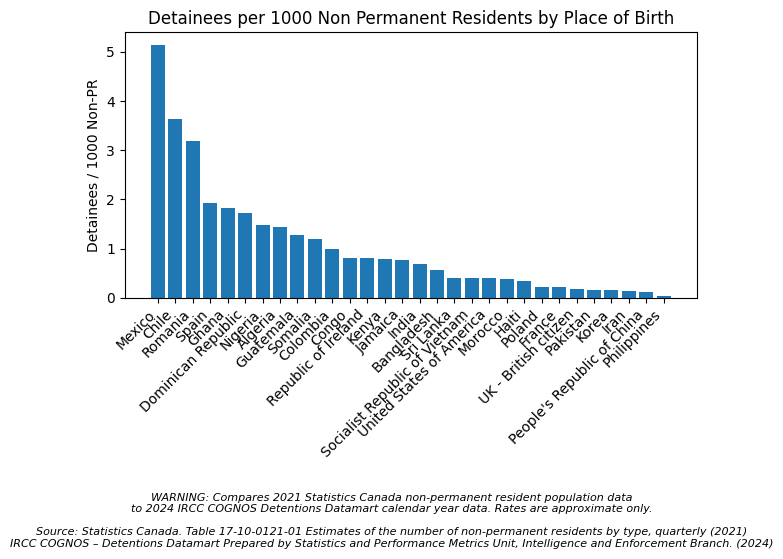

In [73]:
fig, ax = plt.subplots()

ax.bar(df["Nation"].apply(lambda x: x.split(",")[0]), df["Detainees_per_1000"])

ax.set_title("Detainees per 1000 Non Permanent Residents by Place of Birth")
# ax.set_xlabel("Place of Birth")
ax.set_ylabel("Detainees / 1000 Non-PR")

plt.xticks(rotation=45, ha="right")
plt.subplots_adjust(bottom=0.35)

plt.figtext(
    0.5, -0.15,
    "WARNING: Compares 2021 Statistics Canada non-permanent resident population data\n"
    "to 2024 IRCC COGNOS Detentions Datamart calendar year data. Rates are approximate only.\n\n"
    "Source: Statistics Canada. Table 17-10-0121-01 Estimates of the number of non-permanent residents by type, quarterly (2021)\n"
    "IRCC COGNOS – Detentions Datamart Prepared by Statistics and Performance Metrics Unit, Intelligence and Enforcement Branch. (2024)",
    ha="center",
    fontsize=8,
    style="italic"
)

plt.tight_layout()
plt.show()

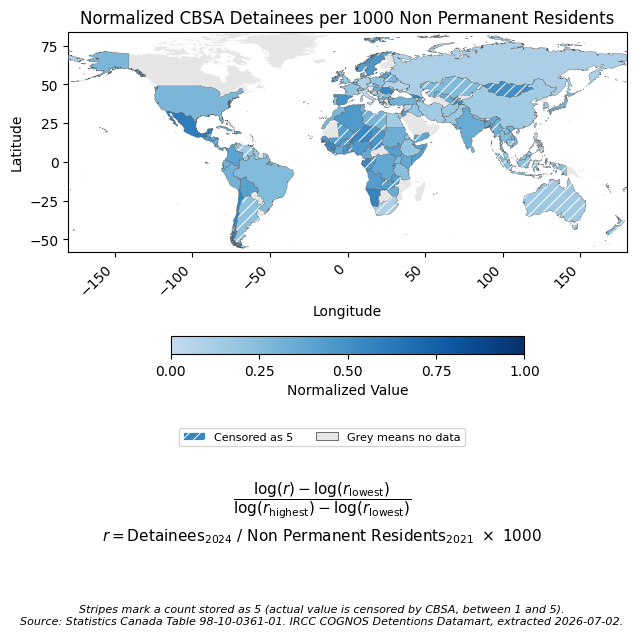

In [74]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import requests
from matplotlib.cm import ScalarMappable
from matplotlib.collections import PolyCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch

# Natural Earth 1:50m, same boundaries as the immigrant visa pause map.
# https://www.naturalearthdata.com/
cache_path = Path("cache") / "ne_50m_admin_0_countries.geojson"
if not cache_path.exists():
    cache_path.parent.mkdir(exist_ok=True)
    url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    cache_path.write_bytes(response.content)

def feature_code(props):
    iso = props.get("ISO_A3")
    if iso and iso != "-99":
        return iso
    return props.get("ADM0_A3")

def exteriors(geometry):
    kind = geometry["type"]
    coords = geometry["coordinates"]
    if kind == "Polygon":
        polygons = [coords]
    elif kind == "MultiPolygon":
        polygons = coords
    else:
        polygons = []
    for polygon in polygons:
        if not polygon:
            continue
        current = []
        prev_lon = None
        for point in polygon[0]:
            lon, lat = point[0], point[1]
            if prev_lon is not None and abs(lon - prev_lon) > 180 and len(current) >= 3:
                yield current
                current = []
            current.append((lon, lat))
            prev_lon = lon
        if len(current) >= 3:
            yield current

# Detainee citizenship -> 2021 census place of birth, Natural Earth code.
# France and Norway use ADM0_A3 because ISO_A3 is -99. South Sudan uses ISO_A3 SSD.
# Counts stored as 5 are censored. They use that count on the same scale, with white stripes.
country_crosswalk = {
    "Afghanistan": ("Afghanistan", "AFG"),
    "Albania": ("Albania", "ALB"),
    "Algeria": ("Algeria", "DZA"),
    "Angola": ("Angola", "AGO"),
    "Antigua and Barbuda": ("Antigua and Barbuda", "ATG"),
    "Argentina": ("Argentina", "ARG"),
    "Australia": ("Australia", "AUS"),
    "Azerbaijan": ("Azerbaijan", "AZE"),
    "Bahama Islands, The": ("Bahamas", "BHS"),
    "Bahrain": ("Bahrain", "BHR"),
    "Bangladesh": ("Bangladesh", "BGD"),
    "Barbados": ("Barbados", "BRB"),
    "Belarus": ("Belarus", "BLR"),
    "Belgium": ("Belgium", "BEL"),
    "Belize": ("Belize", "BLZ"),
    "Bermuda": ("Bermuda", "BMU"),
    "Bolivia": ("Bolivia", "BOL"),
    "Bosnia-Hercegovina": ("Bosnia and Herzegovina", "BIH"),
    "Brazil": ("Brazil", "BRA"),
    "Bulgaria": ("Bulgaria", "BGR"),
    "Burkina-Faso": ("Burkina Faso", "BFA"),
    "Burundi": ("Burundi", "BDI"),
    "Cambodia": ("Cambodia", "KHM"),
    "Cape Verde Islands": ("Cabo Verde", "CPV"),
    "Chad, Republic of": ("Chad", "TCD"),
    "Chile": ("Chile", "CHL"),
    "Colombia": ("Colombia", "COL"),
    "Congo, Democratic Republic of the": ("Congo, Democratic Republic of the", "COD"),
    "Congo, People's Republic of the": ("Congo, Republic of the", "COG"),
    "Costa Rica": ("Costa Rica", "CRI"),
    "Croatia": ("Croatia", "HRV"),
    "Cuba": ("Cuba", "CUB"),
    "Cyprus": ("Cyprus", "CYP"),
    "Czech Republic": ("Czechia", "CZE"),
    "Democratic Republic of Sudan": ("Sudan", "SDN"),
    "Denmark": ("Denmark", "DNK"),
    "Dominica": ("Dominica", "DMA"),
    "Dominican Republic": ("Dominican Republic", "DOM"),
    "Ecuador": ("Ecuador", "ECU"),
    "Egypt": ("Egypt", "EGY"),
    "El Salvador": ("El Salvador", "SLV"),
    "Eritrea": ("Eritrea", "ERI"),
    "Ethiopia": ("Ethiopia", "ETH"),
    "Federal Republic of Cameroon": ("Cameroon", "CMR"),
    "Federal Republic of Germany": ("Germany", "DEU"),
    "Fiji": ("Fiji", "FJI"),
    "France": ("France", "FRA"),
    "Gabon Republic": ("Gabon", "GAB"),
    "Gambia": ("Gambia", "GMB"),
    "Georgia": ("Georgia", "GEO"),
    "Ghana": ("Ghana", "GHA"),
    "Greece": ("Greece", "GRC"),
    "Guatemala": ("Guatemala", "GTM"),
    "Guinea, Republic of": ("Guinea", "GIN"),
    "Guyana": ("Guyana", "GUY"),
    "Haiti": ("Haiti", "HTI"),
    "Honduras": ("Honduras", "HND"),
    "Hong Kong SAR": ("Hong Kong", "HKG"),
    "Hungary": ("Hungary", "HUN"),
    "India": ("India", "IND"),
    "Iran": ("Iran", "IRN"),
    "Iraq": ("Iraq", "IRQ"),
    "Israel": ("Israel", "ISR"),
    "Italy": ("Italy", "ITA"),
    "Jamaica": ("Jamaica", "JAM"),
    "Japan": ("Japan", "JPN"),
    "Jordan": ("Jordan", "JOR"),
    "Kazakhstan": ("Kazakhstan", "KAZ"),
    "Kenya": ("Kenya", "KEN"),
    "Korea, Republic of": ("Korea, South", "KOR"),
    "Laos": ("Laos", "LAO"),
    "Latvia": ("Latvia", "LVA"),
    "Lebanon": ("Lebanon", "LBN"),
    "Liberia": ("Liberia", "LBR"),
    "Libya": ("Libya", "LBY"),
    "Lithuania": ("Lithuania", "LTU"),
    "Macedonia": ("North Macedonia", "MKD"),
    "Malaysia": ("Malaysia", "MYS"),
    "Mali, Republic of": ("Mali", "MLI"),
    "Malta": ("Malta", "MLT"),
    "Mauritius": ("Mauritius", "MUS"),
    "Mexico": ("Mexico", "MEX"),
    "Moldova": ("Moldova", "MDA"),
    "Mongolia, People's Republic of": ("Mongolia", "MNG"),
    "Morocco": ("Morocco", "MAR"),
    "Myanmar (Burma)": ("Myanmar", "MMR"),
    "Namibia": ("Namibia", "NAM"),
    "Nepal": ("Nepal", "NPL"),
    "New Zealand": ("New Zealand", "NZL"),
    "Nicaragua": ("Nicaragua", "NIC"),
    "Nigeria": ("Nigeria", "NGA"),
    "Norway": ("Norway", "NOR"),
    "Pakistan": ("Pakistan", "PAK"),
    "Palestinian Authority (Gaza/West Bank)": ("West Bank and Gaza Strip", "PSE"),
    "Panama, Republic of": ("Panama", "PAN"),
    "People's Republic of Benin": ("Benin", "BEN"),
    "People's Republic of China": ("China", "CHN"),
    "Peru": ("Peru", "PER"),
    "Philippines": ("Philippines", "PHL"),
    "Poland": ("Poland", "POL"),
    "Portugal": ("Portugal", "PRT"),
    "Republic of Djibouti": ("Djibouti", "DJI"),
    "Republic of Indonesia": ("Indonesia", "IDN"),
    "Republic of Ireland": ("Ireland", "IRL"),
    "Republic of Ivory Coast": ("Côte d'Ivoire", "CIV"),
    "Republic of South Africa": ("South Africa, Republic of", "ZAF"),
    "Republic of the Niger": ("Niger", "NER"),
    "Romania": ("Romania", "ROU"),
    "Russia": ("Russian Federation", "RUS"),
    "Rwanda": ("Rwanda", "RWA"),
    "Senegal": ("Senegal", "SEN"),
    "Serbia, Republic of": ("Serbia", "SRB"),
    "Sierra Leone": ("Sierra Leone", "SLE"),
    "Singapore": ("Singapore", "SGP"),
    "Slovak Republic": ("Slovakia", "SVK"),
    "Socialist Republic of Vietnam": ("Viet Nam", "VNM"),
    "Somalia, Democratic Republic of": ("Somalia", "SOM"),
    "South Sudan, Republic of": ("South Sudan", "SSD"),
    "Spain": ("Spain", "ESP"),
    "Sri Lanka": ("Sri Lanka", "LKA"),
    "St. Kitts-Nevis": ("Saint Kitts and Nevis", "KNA"),
    "St. Lucia": ("Saint Lucia", "LCA"),
    "St. Vincent and the Grenadines": ("Saint Vincent and the Grenadines", "VCT"),
    "Sweden": ("Sweden", "SWE"),
    "Switzerland": ("Switzerland", "CHE"),
    "Syria": ("Syria", "SYR"),
    "Taiwan": ("Taiwan", "TWN"),
    "Tajikistan": ("Tajikistan", "TJK"),
    "Thailand": ("Thailand", "THA"),
    "The Netherlands": ("Netherlands", "NLD"),
    "Togo, Republic of": ("Togo", "TGO"),
    "Trinidad and Tobago, Republic of": ("Trinidad and Tobago", "TTO"),
    "Tunisia": ("Tunisia", "TUN"),
    "Turkey": ("Turkey", "TUR"),
    "Uganda": ("Uganda", "UGA"),
    "UK - British citizen": ("United Kingdom", "GBR"),
    "Ukraine": ("Ukraine", "UKR"),
    "United Republic of Tanzania": ("Tanzania", "TZA"),
    "United States of America": ("United States of America", "USA"),
    "Uzbekistan": ("Uzbekistan", "UZB"),
    "Vanuatu": ("Vanuatu", "VUT"),
    "Venezuela": ("Venezuela", "VEN"),
    "Yemen, Republic of": ("Yemen", "YEM"),
    "Zambia": ("Zambia", "ZMB"),
    "Zimbabwe": ("Zimbabwe", "ZWE"),
}
not_a_country = {
    "British Dependent Territories Citizen",
    "Canada",
    "Stateless",
    "UK - Brit. Nat. Overseas",
    "United Kingdom and Colonies",
    "Unknown",
}
unknown_citizenship = sorted(
    set(df_detainees_2024_original["Citizenship"]) - set(country_crosswalk) - not_a_country
)
if unknown_citizenship:
    raise ValueError(unknown_citizenship)

value_col = "Non-permanent resident type (10):Total - Non-permanent resident type[1]"
population = df_birth_2021_canada_nations_clean_original[
    ["Place of birth (290)", value_col]
].rename(columns={"Place of birth (290)": "Census", value_col: "Population"})
if population["Census"].duplicated().any():
    raise ValueError("Repeated place of birth")

mapped = df_detainees_2024_original[
    df_detainees_2024_original["Citizenship"].isin(country_crosswalk)
].copy()
mapped["Censored"] = mapped["Detainees"] == 5
mapped["Census"] = mapped["Citizenship"].map(lambda name: country_crosswalk[name][0])
mapped["Code"] = mapped["Citizenship"].map(lambda name: country_crosswalk[name][1])
mapped = mapped.merge(population, on="Census", how="left")
if mapped["Population"].isna().any() or (mapped["Population"] <= 0).any():
    raise ValueError(mapped.loc[mapped["Population"].isna() | (mapped["Population"] <= 0), "Citizenship"].tolist())
mapped["Detainees_per_1000"] = (mapped["Detainees"] / mapped["Population"]) * 1000
if mapped.loc[mapped["Censored"], "Code"].isin(mapped.loc[~mapped["Censored"], "Code"]).any():
    raise ValueError("Censored and exact counts share a map code")

# A stored 5 is the count used for the rate. Stripes mark that it is censored.
# Log keeps one very high rate from painting the other countries the same color.
rates = mapped["Detainees_per_1000"]
log_rates = rates.map(math.log)
log_min = float(log_rates.min())
log_max = float(log_rates.max())
span = log_max - log_min
if span == 0:
    normalized = rates * 0 + 1.0
else:
    # Scale the lowest log rate to 0 and the highest to 1.
    normalized = (log_rates - log_min) / span
by_code = dict(zip(mapped["Code"], normalized))
censored_codes = set(mapped.loc[mapped["Censored"], "Code"])

world = json.loads(cache_path.read_text(encoding="utf-8"))
found = set()
other = []
exact_rings = []
exact_colors = []
censored_rings = []
censored_colors = []
# Light to dark blue so the middle stays readable without a warning color.
cmap = LinearSegmentedColormap.from_list(
    "detainees",
    [plt.cm.Blues(step) for step in (0.25, 0.4, 0.55, 0.7, 0.85, 1.0)],
)
for feature in world["features"]:
    code = feature_code(feature["properties"])
    if code == "ATA":
        continue
    parts = list(exteriors(feature["geometry"]))
    if code in by_code:
        value = float(by_code[code])
        found.add(code)
        censored = code in censored_codes
    elif code == "SOL" and "SOM" in by_code:
        # Natural Earth draws Somaliland separately. The rate is for Somalia.
        value = float(by_code["SOM"])
        censored = "SOM" in censored_codes
    else:
        other.extend(parts)
        continue
    color = cmap(value)
    if censored:
        ring_list, color_list = censored_rings, censored_colors
    else:
        ring_list, color_list = exact_rings, exact_colors
    for part in parts:
        ring_list.append(part)
        color_list.append(color)

missing = sorted(set(by_code) - found)
if missing:
    raise ValueError(missing)

fig, ax = plt.subplots()
ax.add_collection(PolyCollection(other, facecolor="#e6e6e6", edgecolor="white", linewidths=0.2))
if exact_rings:
    ax.add_collection(
        PolyCollection(exact_rings, facecolors=exact_colors, edgecolors="#555555", linewidths=0.25, zorder=3)
    )
if censored_rings:
    ax.add_collection(
        PolyCollection(
            censored_rings,
            facecolors=censored_colors,
            edgecolors="#555555",
            linewidths=0.25,
            zorder=3,
        )
    )
    # White stripes over the same blue. The border stays on the fill underneath.
    plt.rcParams["hatch.linewidth"] = 0.7
    ax.add_collection(
        PolyCollection(
            censored_rings,
            facecolors="none",
            edgecolors="white",
            linewidths=0,
            hatch="///",
            zorder=4,
        )
    )
ax.set_xlim(-180, 180)
ax.set_ylim(-58, 84)
ax.set_aspect("equal", adjustable="box")
ax.set_title("Normalized CBSA Detainees per 1000 Non Permanent Residents")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.xticks(rotation=45, ha="right")
scale = ScalarMappable(norm=Normalize(vmin=0, vmax=1), cmap=cmap)
scale.set_array([])
color_bar = fig.colorbar(scale, ax=ax, orientation="horizontal", fraction=0.046, pad=0.22)
color_bar.set_ticks([0, 0.25, 0.5, 0.75, 1])
color_bar.set_label("Normalized Value")
fig.legend(
    handles=[
        Patch(
            facecolor=cmap(0.55),
            edgecolor="white",
            linewidth=0.6,
            hatch="///",
            label="Censored as 5",
        ),
        Patch(
            facecolor="#e6e6e6",
            edgecolor="#555555",
            linewidth=0.6,
            label="Grey means no data",
        ),
    ],
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
    ncol=2,
    frameon=True,
    fontsize=8,
)
plt.subplots_adjust(bottom=0.34)
# Mathtext at the note size, and italic on the same string, draws the years on the baseline.
plt.figtext(
    0.5, -0.14,
    r"$\dfrac{\log(r)-\log(r_{\mathrm{lowest}})}{\log(r_{\mathrm{highest}})-\log(r_{\mathrm{lowest}})}$"
    "\n"
    r"$r=\mathrm{Detainees}_{2024}\ /\ \mathrm{Non\ Permanent\ Residents}_{2021}\ \times\ 1000$",
    ha="center",
    va="top",
    fontsize=11,
    linespacing=1.5,
)
plt.figtext(
    0.5, -0.40,
    "Stripes mark a count stored as 5 (actual value is censored by CBSA, between 1 and 5).\n"
    "Source: Statistics Canada Table 98-10-0361-01. IRCC COGNOS Detentions Datamart, extracted 2026-07-02.",
    ha="center",
    va="top",
    fontsize=8,
    style="italic",
)
plt.tight_layout()
plt.show()


In [75]:
df

,Nation,Population,Detainees,Detainees_per_1000
13,Mexico,132220,680,5.142944
25,Chile,31565,115,3.643276
18,Romania,88645,282,3.181228
29,Spain,15025,29,1.930116
26,Ghana,29110,53,1.820680
28,Dominican Republic,15640,27,1.726343
15,Nigeria,111470,165,1.480219
19,Algeria,87835,127,1.445893
27,Guatemala,21150,27,1.276596
23,"Somalia, Democratic Republic of",34115,41,1.201817


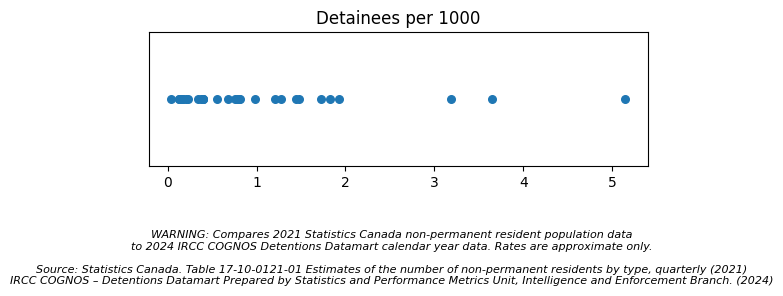

In [76]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()

y = np.zeros(len(df))
ax.scatter(df["Detainees_per_1000"], y, s=30)

ax.set_yticks([])
ax.set_title("Detainees per 1000")
# ax.set_xlabel("Detainees per 1000")
ax.set_ylabel("")

plt.figtext(
    0.5, 0.175,
    "WARNING: Compares 2021 Statistics Canada non-permanent resident population data\n"
    "to 2024 IRCC COGNOS Detentions Datamart calendar year data. Rates are approximate only.\n\n"
    "Source: Statistics Canada. Table 17-10-0121-01 Estimates of the number of non-permanent residents by type, quarterly (2021)\n"
    "IRCC COGNOS – Detentions Datamart Prepared by Statistics and Performance Metrics Unit, Intelligence and Enforcement Branch. (2024)",
    ha="center",
    fontsize=8,
    style="italic"
)

plt.tight_layout()

# Force a shorter axes box (this overrides tight_layout)
ax.set_position([0.12, 0.42, 0.78, 0.28])

plt.show()

In [77]:
df[df["Detainees_per_1000"] > 3]

,Nation,Population,Detainees,Detainees_per_1000
13,Mexico,132220,680,5.142944
25,Chile,31565,115,3.643276
18,Romania,88645,282,3.181228


In [78]:
df_outliers = df[~(df["Detainees_per_1000"] > 3)]
df_outliers

,Nation,Population,Detainees,Detainees_per_1000
29,Spain,15025,29,1.930116
26,Ghana,29110,53,1.820680
28,Dominican Republic,15640,27,1.726343
15,Nigeria,111470,165,1.480219
19,Algeria,87835,127,1.445893
27,Guatemala,21150,27,1.276596
23,"Somalia, Democratic Republic of",34115,41,1.201817
16,Colombia,99170,98,0.988202
21,"Congo, Democratic Republic of the",39475,32,0.810640
22,Republic of Ireland,34950,28,0.801144


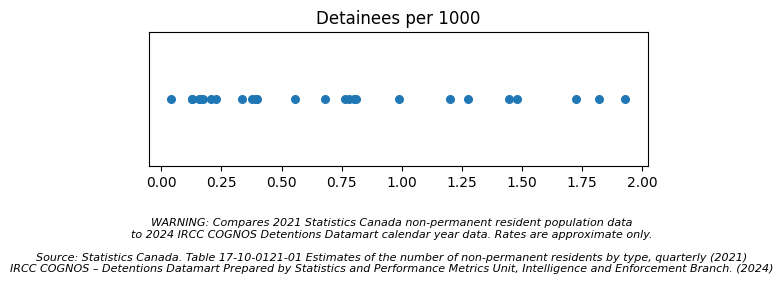

In [79]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()

y = np.zeros(len(df_outliers))
ax.scatter(df_outliers["Detainees_per_1000"], y, s=30)

ax.set_yticks([])
ax.set_title("Detainees per 1000")
# ax.set_xlabel("Detainees per 1000")
ax.set_ylabel("")

plt.figtext(
    0.5, 0.2,
    "WARNING: Compares 2021 Statistics Canada non-permanent resident population data\n"
    "to 2024 IRCC COGNOS Detentions Datamart calendar year data. Rates are approximate only.\n\n"
    "Source: Statistics Canada. Table 17-10-0121-01 Estimates of the number of non-permanent residents by type, quarterly (2021)\n"
    "IRCC COGNOS – Detentions Datamart Prepared by Statistics and Performance Metrics Unit, Intelligence and Enforcement Branch. (2024)",
    ha="center",
    fontsize=8,
    style="italic"
)

plt.tight_layout()

# Force a shorter axes box (this overrides tight_layout)
ax.set_position([0.12, 0.42, 0.78, 0.28])

plt.show()

In [80]:
df_outliers["Nation"].unique().tolist()

['Spain',
 'Ghana',
 'Dominican Republic',
 'Nigeria',
 'Algeria',
 'Guatemala',
 'Somalia, Democratic Republic of',
 'Colombia',
 'Congo, Democratic Republic of the',
 'Republic of Ireland',
 'Kenya',
 'Jamaica',
 'India',
 'Bangladesh',
 'Sri Lanka',
 'Socialist Republic of Vietnam',
 'United States of America',
 'Morocco',
 'Haiti',
 'Poland',
 'France',
 'UK - British citizen',
 'Pakistan',
 'Korea, Republic of',
 'Iran',
 "People's Republic of China",
 'Philippines']

In [81]:
continent_map = {
    "Ghana": "Africa",
    "Nigeria": "Africa",
    "Algeria": "Africa",
    "Somalia, Democratic Republic of": "Africa",
    "Congo, Democratic Republic of the": "Africa",
    "Kenya": "Africa",
    "Morocco": "Africa",

    "Spain": "Europe",
    "Republic of Ireland": "Europe",
    "Poland": "Europe",
    "France": "Europe",
    "UK - British citizen": "Europe",
    "United States of America": "Europe",

    "India": "South Asia",
    "Bangladesh": "South Asia",
    "Sri Lanka": "South Asia",
    "Pakistan": "South Asia",

    "Socialist Republic of Vietnam": "East Asia",
    "Korea, Republic of": "East Asia",
    "People's Republic of China": "East Asia",
    "Philippines": "East Asia",
    "Iran": "East Asia",

    "Dominican Republic": "Latin America",
    "Colombia": "Latin America",
    "Guatemala": "Latin America",

    "Jamaica": "Caribbean",
    "Haiti": "Caribbean"
}

df_outliers["Continent"] = df_outliers["Nation"].map(continent_map)
df_outliers

C:\Users\D\AppData\Local\Temp\ipykernel_27732\1628856549.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_outliers["Continent"] = df_outliers["Nation"].map(continent_map)


,Nation,Population,Detainees,Detainees_per_1000,Continent
29,Spain,15025,29,1.930116,Europe
26,Ghana,29110,53,1.820680,Africa
28,Dominican Republic,15640,27,1.726343,Latin America
15,Nigeria,111470,165,1.480219,Africa
19,Algeria,87835,127,1.445893,Africa
27,Guatemala,21150,27,1.276596,Latin America
23,"Somalia, Democratic Republic of",34115,41,1.201817,Africa
16,Colombia,99170,98,0.988202,Latin America
21,"Congo, Democratic Republic of the",39475,32,0.810640,Africa
22,Republic of Ireland,34950,28,0.801144,Europe


In [82]:
set(list(continent_map.values()))

{'Africa', 'Caribbean', 'East Asia', 'Europe', 'Latin America', 'South Asia'}

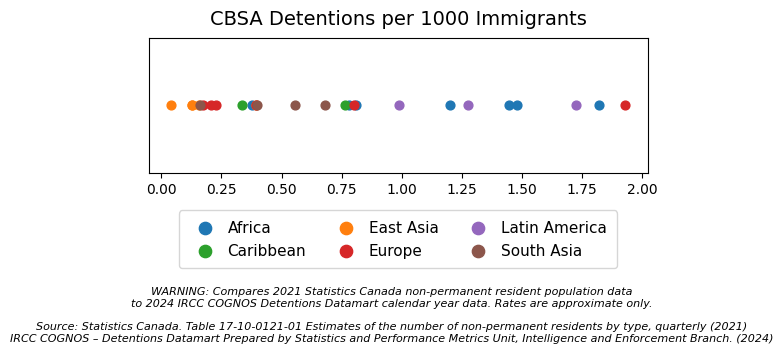

In [83]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()

# Color mapping for the continents
color_map = {
    "Africa": "tab:blue",
    "East Asia": "tab:orange",
    "Caribbean": "tab:green",
    "Europe": "tab:red",
    "Latin America": "tab:purple",
    "South Asia": "tab:brown"
}

# Plot each continent group with its color
for continent, group in df_outliers.groupby("Continent"):
    ax.scatter(
        group["Detainees_per_1000"],
        np.zeros(len(group)),
        s=40,
        label=continent,
        color=color_map.get(continent, "gray")
    )
ax.set_yticks([])
ax.set_title("CBSA Detentions per 1000 Immigrants", fontsize=14, pad=10)
ax.set_ylabel("")

ax.legend(
    title=None,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.225),
    ncol=3,
    frameon=True,
    fontsize=11,          # bigger legend text
    markerscale=1.4,
    handletextpad=0.5,
    columnspacing=1.6,
    borderpad=0.65,
)

# Wide axes box. Do NOT use ax.set_position(...) — that was shrinking the plot.
fig.subplots_adjust(left=0.05, right=0.98, top=0.91, bottom=0.40)

plt.figtext(
    0.5, 0.125,
    "WARNING: Compares 2021 Statistics Canada non-permanent resident population data\n"
    "to 2024 IRCC COGNOS Detentions Datamart calendar year data. Rates are approximate only.\n\n"
    "Source: Statistics Canada. Table 17-10-0121-01 Estimates of the number of non-permanent residents by type, quarterly (2021)\n"
    "IRCC COGNOS – Detentions Datamart Prepared by Statistics and Performance Metrics Unit, Intelligence and Enforcement Branch. (2024)",
    ha="center",
    va="bottom",
    fontsize=8,
    style="italic",
)

plt.tight_layout()

# Force a shorter axes box
ax.set_position([0.12, 0.48, 0.78, 0.28])

plt.show()

In [84]:
df_outliers[(df_outliers["Detainees_per_1000"] > 1.75) & (df_outliers["Continent"] == "Europe")]

,Nation,Population,Detainees,Detainees_per_1000,Continent
29,Spain,15025,29,1.930116,Europe


In [85]:
df_outliers[(df_outliers["Detainees_per_1000"] < 1.75) & (df_outliers["Continent"] == "Europe")]

,Nation,Population,Detainees,Detainees_per_1000,Continent
22,Republic of Ireland,34950,28,0.801144,Europe
4,United States of America,373380,147,0.393701,Europe
12,Poland,137605,31,0.225283,Europe
8,France,177715,37,0.208199,Europe
3,UK - British citizen,506035,87,0.171925,Europe
